<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Standard_Problem_4_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

In [2]:
from mumaxplus import *
from mumaxplus.util import plot_field

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['figure.dpi'] = 200

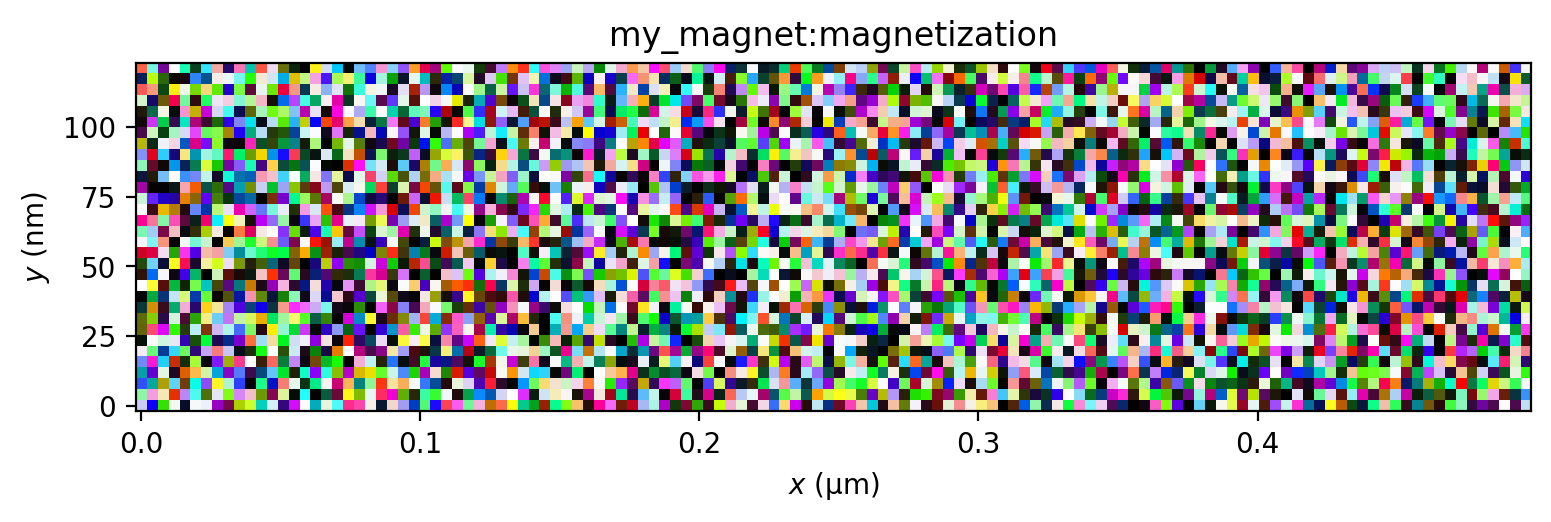

In [4]:
length, width, thickness = 500e-9, 125e-9, 3e-9
nx, ny, nz = 128, 32, 1

world = World(cellsize=(length/nx, width/ny, thickness/nz))

magnet = Ferromagnet(world, Grid((nx, ny, nz)), name="my_magnet")

magnet.msat = 800e3
magnet.aex = 13e-12
magnet.alpha = 0.02

plot_field(magnet.magnetization, enable_quiver=False)
plt.show()

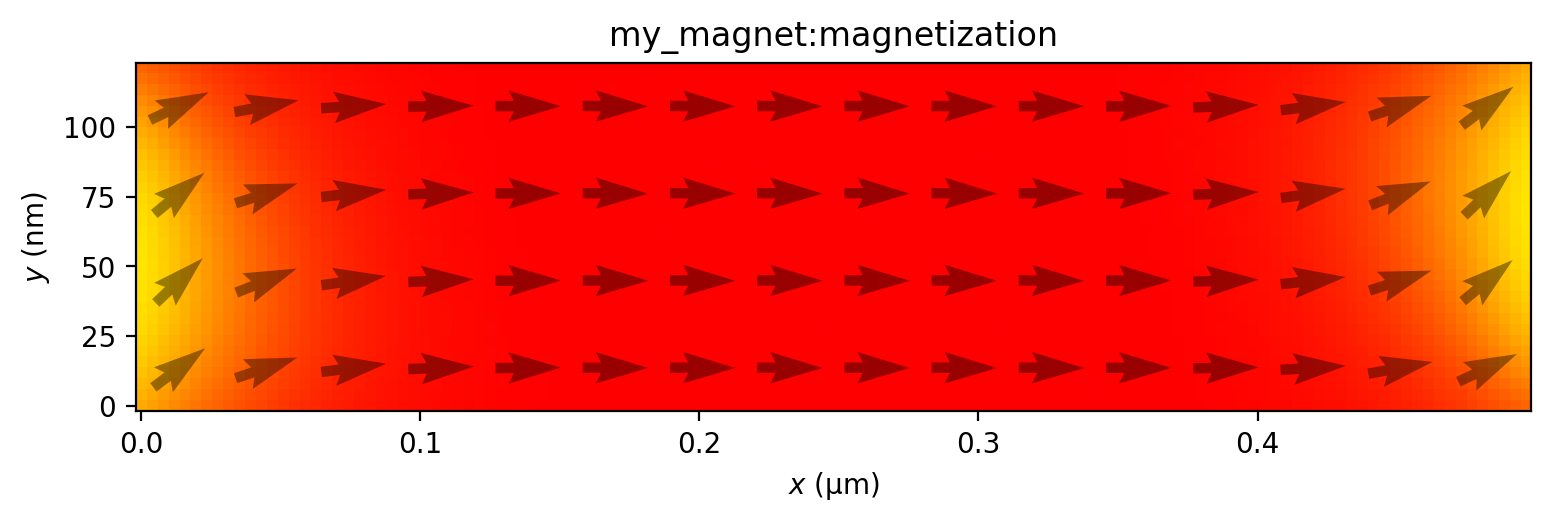

In [7]:
magnet.magnetization = (1, 0.1, 0)
magnet.minimize()

plot_field(magnet.magnetization)
plt.show()

In [8]:
world.bias_magnetic_field = (-24.6e-3, 4.3e-3, 0)
#world.bias_magnetic_field = (-35.5e-3, -6.3e-3, 0)

In [9]:
timepoints = np.linspace(0, 1e-9, 200)
outputquantities = {
    "mx": lambda: magnet.magnetization.average()[0],
    "my": lambda: magnet.magnetization.average()[1],
    "mz": lambda: magnet.magnetization.average()[2],
    "e_total": magnet.total_energy,
    "e_exchange": magnet.exchange_energy,
    "e_zeeman": magnet.zeeman_energy,
    "e_demag": magnet.demag_energy
}

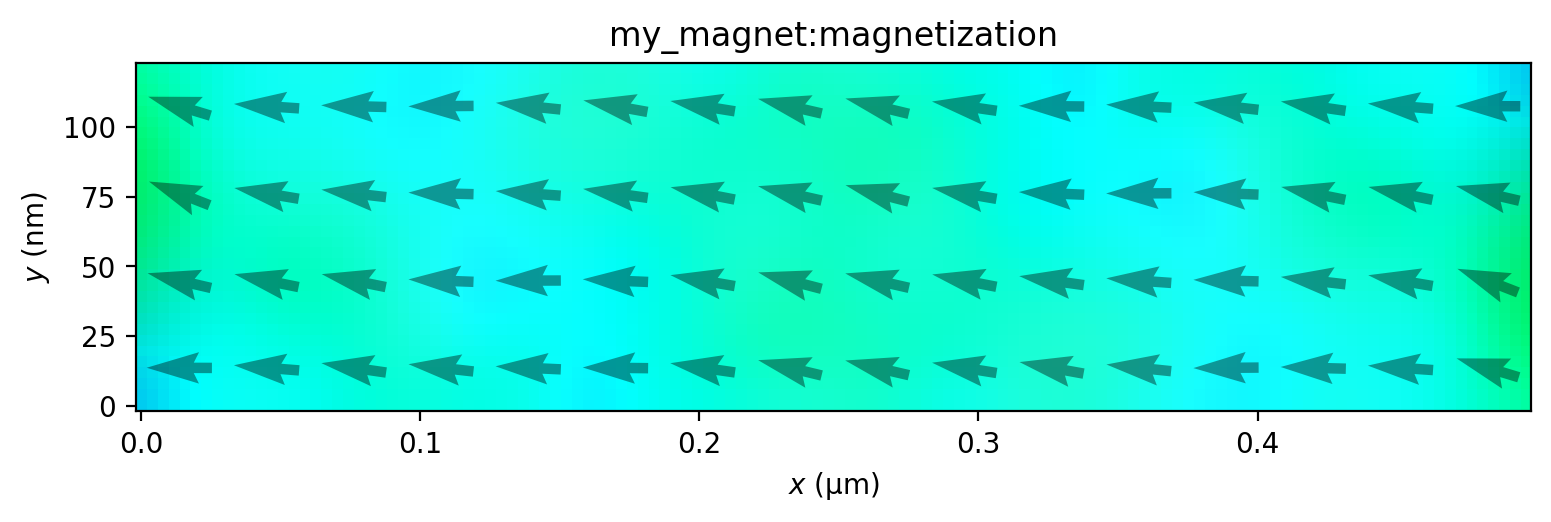

In [10]:
output = world.timesolver.solve(timepoints, outputquantities)

plot_field(magnet.magnetization)
plt.show()

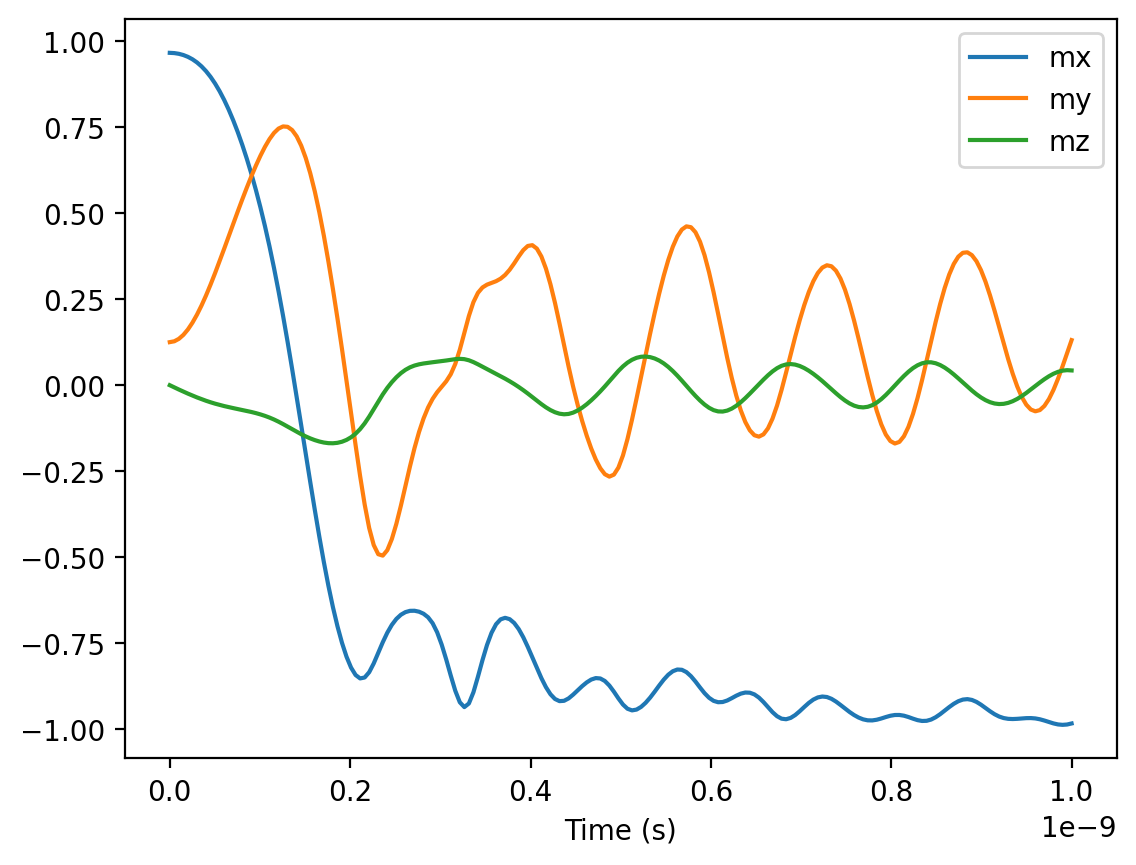

In [11]:
for key in ["mx", "my", "mz"]:
  plt.plot(timepoints, output[key], label=key)

plt.xlabel("Time (s)")
plt.legend()
plt.show()

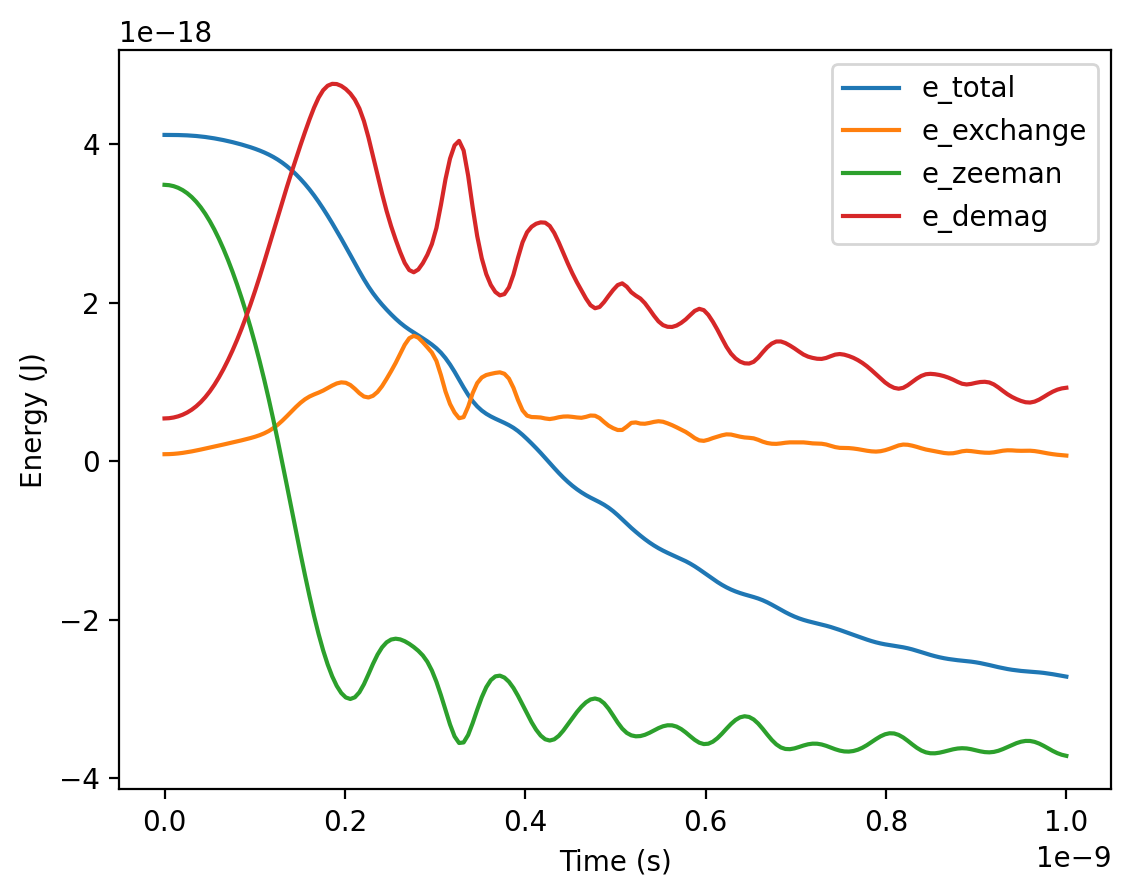

In [12]:
for key in ["e_total", "e_exchange", "e_zeeman", "e_demag"]:
  plt.plot(timepoints, output[key], label=key)

plt.xlabel("Time (s)")
plt.ylabel("Energy (J)")
plt.legend()
plt.show()